# Step 2 - Normalization of the data

After performing the quality controls that enabled to filter out 'bad' cells, it is necessary to normalize the data and select the most important features that will later be used for the analysis. The normalization step is essential to compensate for experimental differeneces.

To run this notebook, use the data_treatment_env and run cells from top to bottom.

## 1. Load the modules & data

### 1.1 Load the data into a practical format

In [1]:
import pandas as pd
import numpy as np
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
%load_ext rpy2.ipython

In [3]:
#Read the csv files

chevalier_path = "../Data/nestorowa_singlecell_raw_data_taken_from_bonesis_paper.tsv"
QC_filtered_cells_path = "../Results/Data_treatment_outputs/cell_QC_filtered_data.tsv.gz"
qc_metrics_path = "../Results/Data_treatment_outputs/cell_QC_metrics.tsv.gz"
conversion_table_path = "../Data/ensembl_to_symbol.tsv"

chevalier_df = pd.read_csv(chevalier_path, sep="\t", index_col=0)
df_qc_filtered_data = pd.read_csv(QC_filtered_cells_path, sep="\t", index_col=0,compression="gzip")
qc_metrics_df = pd.read_csv(qc_metrics_path, sep="\t", index_col=0, compression="gzip")
conversion_table_df = pd.read_csv(conversion_table_path, sep="\t", index_col=0)

# Create a dictionary for quick lookup
id_to_symbol = conversion_table_df['symbol'].to_dict()

In [4]:
#Compare the size of the df
n_genes, n_cells = df_qc_filtered_data.shape

print(f"Chevalier df shape: {chevalier_df.shape}")
print(f"Our Qc-filtered data shape: {df_qc_filtered_data.shape}")

Chevalier df shape: (4768, 1656)
Our Qc-filtered data shape: (43152, 1691)


### 1.2 Filter out low expression genes

The goal here is to get rid of gene that might have a null expression in almost all cells, so that they are not counted as HVG that we will not be able to use in our later analysis.

Text(0, 0.5, 'Frequency')

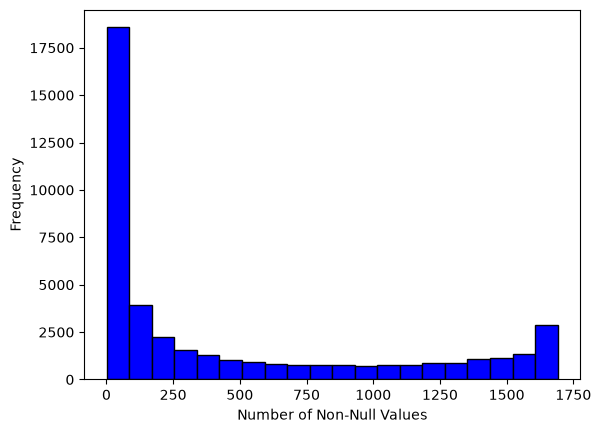

In [5]:
df = df_qc_filtered_data.copy()

#Create a df counting the number of non null values for each row (gene) in the filtered df
non_null_counts =  (df != 0.0).sum(axis=1)


#plot a histogram of the non null counts
import matplotlib.pyplot as plt
non_null_counts.plot(kind="hist", bins=20, edgecolor="black", color="blue")
plt.xlabel("Number of Non-Null Values")
plt.ylabel("Frequency")

In [6]:
# Counting genes with at least xx non-null values (cells)

for k in [0,1,np.floor(n_cells/500),np.floor(n_cells/100), np.floor(n_cells/50),np.floor(n_cells/10)]:
    subset_index = df.index[non_null_counts <= k].tolist()
    count = len(subset_index)

    print(f"Number of genes with measured expression in less or equal than {k} cells: {count}")

Number of genes with measured expression in less or equal than 0 cells: 0
Number of genes with measured expression in less or equal than 1 cells: 1243
Number of genes with measured expression in less or equal than 3.0 cells: 3352
Number of genes with measured expression in less or equal than 16.0 cells: 9765
Number of genes with measured expression in less or equal than 33.0 cells: 13451
Number of genes with measured expression in less or equal than 169.0 cells: 22495


Here we choose to filter out genes that have a measured value in less that 1% of the cells. This is relativelyy arbitrary and could be changed. It is notable that applying this filter considerably enhanced our results and enabled to get more common genes with **Nestorowa et al.** after feature selection.

In [7]:
# Filter genes that are expressed in less than 1% of cells 
filter_rate = np.floor(n_cells/100)
subset_index = df.index[non_null_counts <= filter_rate].tolist()
count = len(subset_index)

df_filtered = df[~df.index.isin(subset_index)]

print(count)
print(df_filtered.shape)

9765
(33387, 1691)


**Load the data into an AnnData object**

The use of scanpy requires to put data in AnnData format. We bind the previously QC filtered data with its metrics to be able to plot some visualisations.

In [8]:
def create_adata(df):
    #Getting data in anndata format
	df_data = df.copy()

	#Converting into int
	float_cols = df_data.select_dtypes(include=['float', 'float64']).columns
	df_data[float_cols] = df_data[float_cols].astype("int64")

	# Get cells in lines and genes in columns
	df_data = df_data.T

	#Filter the qc metrics on the conserved genes
	common_cells = df_data.index.intersection(qc_metrics_df.index)
	df_metrics_filtered = qc_metrics_df.loc[common_cells]

	adata = ad.AnnData(X=df_data.values, obs=df_metrics_filtered)

	#Get a copy of the original gene names in the var dataframe
	adata.var['gene_names'] = df_data.columns

	#Get a copy of the data
	adata.layers["counts"] = adata.X.copy()

	return adata

In [9]:
adata = create_adata(df_filtered)

#Create one adata per method to avoid kernel crashes
adata_log = adata.copy()
adata_scran = adata.copy()
adata_pearson= adata.copy()

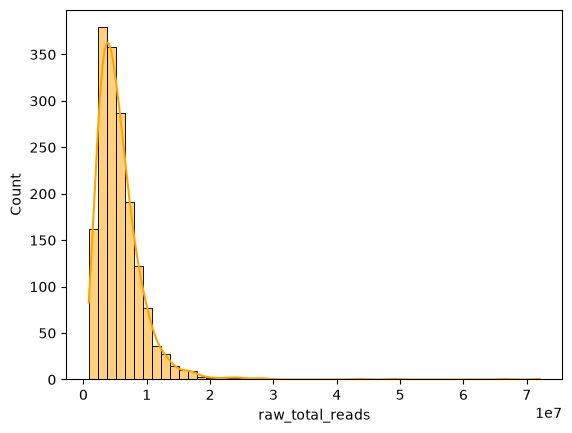

In [10]:
#Visualize the counts distribution
p1= sns.histplot(data=adata.obs, x='raw_total_reads', bins=50, kde=True, color = "orange")

## 2. Normalization of the matrix

The goal of the normalization process i sto compensate for variation due to sampling effects.

Three main methods are mentionned on sc-best-practices.org:
- shifted logarithm
- scran nnormalization
- analytic Pearson's residues approximation.

The article from **Nestorowa et al.** mentions using two processes for normalization:
- resizing the data using an scran method described in **Lun et al. (2016)**
- reshaping the data with a log2 transformation.

This is followed by a feature selection step to consider only the 5000 (in the article 45000) most vaarible genes.

In [11]:
#Define the number of genes that will be selected by the different methods
nb_feature = 5000

### 2.1 Normalization by logarithmic shift

Start by applying the log shift transformation.

In [12]:
scales_counts = sc.pp.normalize_total(adata_log, layer = "counts",target_sum=None, inplace=False)
# log1p transform
adata_log.layers["log1p_norm"] = sc.pp.log1p(scales_counts["X"], copy=True)

**Visualization**

Comparing visually the distribution of the raw counts before and after transformation. Here it is clear that the logarithmic shift enabled to reduce the variance, as intended.

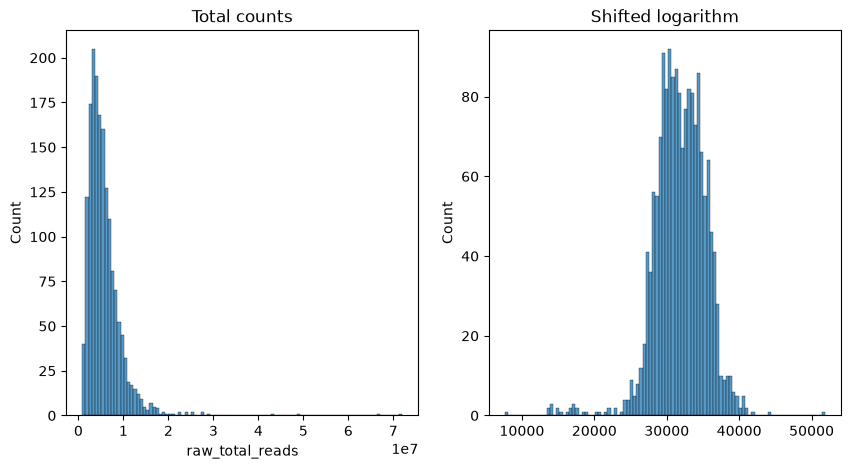

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
p1 = sns.histplot(adata_log.obs["raw_total_reads"], bins=100, kde=False, ax=axes[0])
axes[0].set_title("Total counts")
p2 = sns.histplot(adata_log.layers["log1p_norm"].sum(1), bins=100, kde=False, ax=axes[1])
axes[1].set_title("Shifted logarithm")
plt.savefig("../Results/Data_treatment_outputs/total_counts_histogram_log_shift.png", dpi=300)
plt.show()

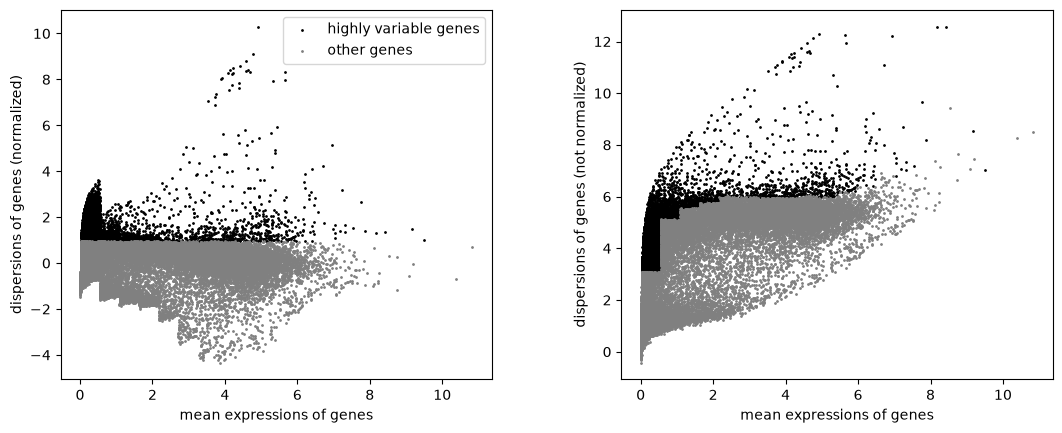

In [15]:
# Computing HVG with the normalized counts
sc.pp.highly_variable_genes(adata_log, layer="log1p_norm", flavor="seurat", n_top_genes=nb_feature)

#Save in a special layer
adata_log.var["hvg_log_shift"]=adata_log.var["highly_variable"].copy()

# Visualisation
sc.pl.highly_variable_genes(adata_log)

In [16]:
#Getting the gene list from adata highly variable, where variable is True
hvg_genes_log = adata_log.var['gene_names'][adata_log.var['highly_variable']].tolist()

#Convert the list with the ensembl ids to gene symbols using the conversion table
hvg_symbols_log = [id_to_symbol.get(gene_id, gene_id) for gene_id in hvg_genes_log]

#Compare the list of hvg_symbols to the list of genes in chevalier_df, and print the number of genes in common
common_genes = set(hvg_symbols_log) & set(chevalier_df.index)
print(f"Number of common genes: {len(common_genes)}")

Number of common genes: 1320


### 2.2 Normalization by scran method

This is the method that was used in **Lun et al.**. It combines normalization by size factore which is computed by pooling cells and deconvoluting results, and a log2 transformation.

However we implement a different verison from the article, using Quick Clustering that enables faste computing. Thus, we do not obtain exactly the same results, but one fourth of the selected features are common with the results from **Lun et al.**.

In [19]:
from scipy.sparse import csr_matrix

In [20]:
%%R
library(scran)
library(BiocParallel)

In [21]:
counts_mtx = adata_scran.layers["counts"].T.copy()

In [ ]:
%%R -i counts_mtx -o size_factors

suppressPackageStartupMessages({
    library(SingleCellExperiment)
    library(scran)
    library(BiocParallel)
})

counts_sparse <- as(counts_mtx, "CsparseMatrix")
sce_obj <- SingleCellExperiment(assays = list(counts = counts_sparse))

# Pre-clustering
set.seed(100)
quick_clusters <- quickCluster(sce_obj)

# Size factors (SerialParam évite les plantages Jupyter)
sf_res <- calculateSumFactors(sce_obj, cluster = quick_clusters, BPPARAM = SerialParam())

# Result
if (inherits(sf_res, "SingleCellExperiment")) {
    size_factors <- as.numeric(sizeFactors(sf_res))
} else {
    size_factors <- as.numeric(sf_res)
}

*N.B.: it sometimes happens that the kernel crashes randomly during execution of this cell. If this happens please restart the kernel, execute the 1. part and directly skip to the 2.2 part (without going through 2.1)*

In [ ]:
from scipy.sparse import issparse

adata.obs["scran_size_factor"] = size_factors
sf_vec = adata.obs["scran_size_factor"].values[:, None]
counts_X = adata.layers["counts"]

# Normalization scran & log2
if issparse(counts_X):
    # (counts / size_factor) then log2(1 + x)
    X_norm = counts_X.multiply(1.0 / sf_vec).tocsr()
    # log2(1 + x) = log1p(x) / ln(2)
    X_norm.data = np.log1p(X_norm.data) / np.log(2)
else:
    X_norm = np.log2((counts_X / sf_vec) + 1.0)

# Save in adata
adata.layers["scran_normalized"] = X_norm
adata.X = X_norm.copy()

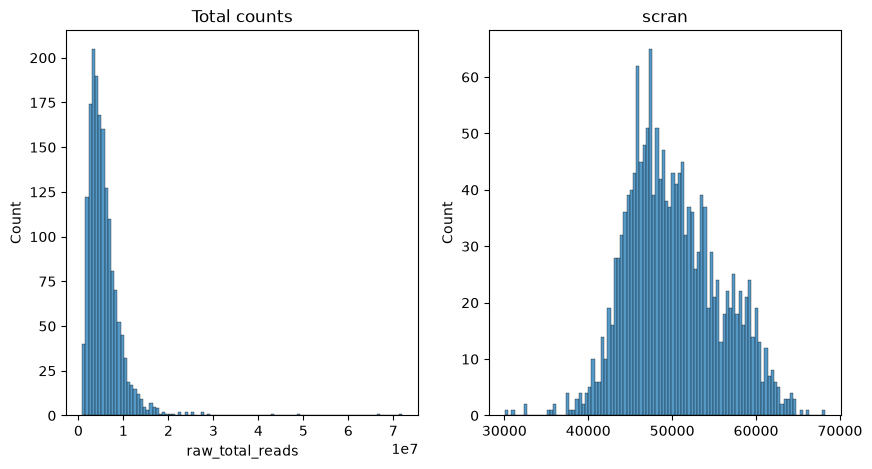

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
p1 = sns.histplot(adata.obs["raw_total_reads"], bins=100, kde=False, ax=axes[0])
axes[0].set_title("Total counts")
p2 = sns.histplot(adata.layers["scran_normalized"].sum(1), bins=100, kde=False, ax=axes[1])
axes[1].set_title("scran")
plt.show()

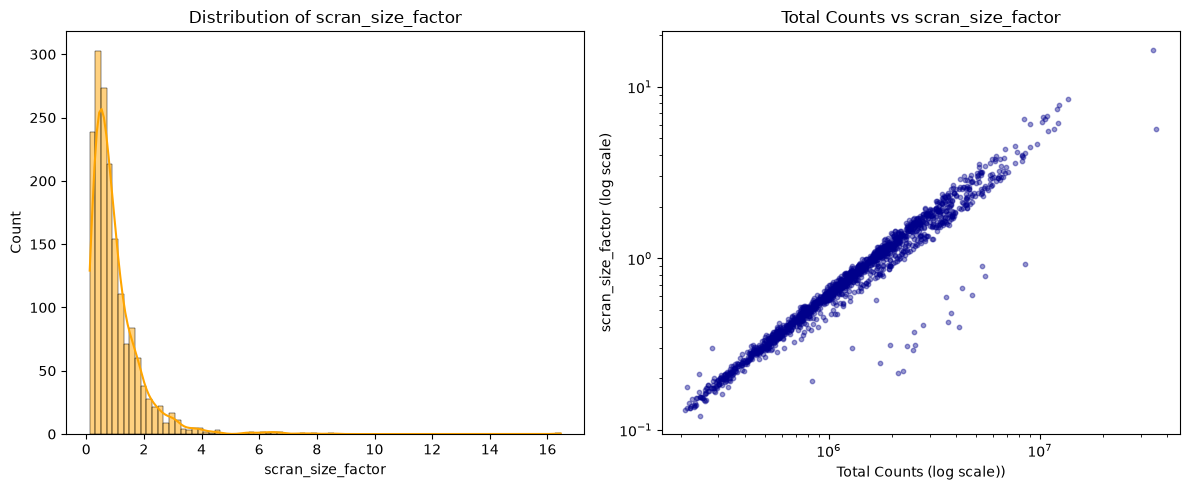

In [18]:
# Adding total counts
if "total_counts" not in adata.obs:
    adata.obs["total_counts"] = (
        adata.layers["counts"].sum(axis=1)
        if "counts" in adata.layers
        else counts_X.sum(axis=1)
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Histogram
sns.histplot(
    adata.obs["scran_size_factor"], kde=True, ax=axes[0], color="orange"
)
axes[0].set_title("Distribution of scran_size_factor")
axes[0].set_xlabel("scran_size_factor")

# Correlation between gene counts and size factor
axes[1].scatter(
    adata.obs["total_counts"],
    adata.obs["scran_size_factor"],
    alpha=0.4,
    s=10,
    c="darkblue",
)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Total Counts (log scale))")
axes[1].set_ylabel("scran_size_factor (log scale)")
axes[1].set_title("Total Counts vs scran_size_factor")

plt.tight_layout()
plt.show()

In [19]:
import scanpy as sc

# Selecting HVG
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=nb_feature,
    flavor="seurat",  # or "cell_ranger"
    layer="scran_normalized",
    subset=False,
)

In [20]:
#Getting the gene list from adata highly variable, where variable is True
hvg_scran = adata.var['gene_names'][adata.var['highly_variable']].tolist()

#Convert the list with the ensembl ids to gene symbols using the conversion table
hvg_symbols_scran = [id_to_symbol.get(gene_id, gene_id) for gene_id in hvg_scran]

#Compare the list of hvg_symbols to the list of genes in chevalier_df, and print the number of genes in common
common_genes = set(hvg_symbols_scran) & set(chevalier_df.index)
print(f"Number of common genes: {len(common_genes)}")

Number of common genes: 1272


### 2.3 Normalization using Pearson's residues

In [ ]:
# Computing pearson's residues
pearson_results = sc.experimental.pp.normalize_pearson_residuals(adata,layer = "counts")

# Selecting HVG
sc.experimental.pp.highly_variable_genes(
    adata,
    layer = "counts", 
    flavor="pearson_residuals", 
    n_top_genes= nb_feature
)

In [ ]:
#Getting the gene list from adata highly variable, where variable is True
hvg_genes_pearson = adata.var['gene_names'][adata.var['highly_variable']].tolist()

#Convert the list with the ensembl ids to gene symbols using the conversion table
hvg_symbols_pearson = [id_to_symbol.get(gene_id, gene_id) for gene_id in hvg_genes_pearson]

#Compare the list of hvg_symbols to the list of genes in chevalier_df, and print the number of genes in common
common_genes = set(hvg_symbols_pearson) & set(chevalier_df.index)
print(f"Number of common genes: {len(common_genes)}")


Number of common genes: 69
